# Notebook 02: On-Device Behavioral Telemetry Exploratory Data Analysis

## 1. Interaction Matrix Sparsity
Given $|\mathcal{U}|$ users and $|\mathcal{I}|$ catalog articles with $|\mathcal{E}|$ recorded reading sessions, interaction sparsity is:
$$S = 1 - \frac{|\mathcal{E}_{\text{unique}}|}{|\mathcal{U}| \cdot |\mathcal{I}|}$$
High sparsity ($> 98\%$) motivates hybrid content-aware modeling with frozen semantic embeddings.

In [1]:
import os, sys, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Resolve repository root deterministically from ml/notebooks/
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

DATA_DIR = os.path.join(REPO_ROOT, "ml", "data", "processed")
ARTIFACTS_DIR = os.path.join(REPO_ROOT, "ml", "artifacts")
VIZ_DIR = os.path.join(REPO_ROOT, "ml", "visualizations")
plt.rcParams["figure.dpi"] = 110
df = pd.read_csv(os.path.join(DATA_DIR, "interactions.csv"))
n_users = df["user_id"].nunique()
n_items = df["article_id"].nunique()
unique_pairs = df[["user_id", "article_id"]].drop_duplicates().shape[0]
sparsity = 1.0 - (unique_pairs / (n_users * 3000))

summary = pd.DataFrame([
    {"Metric": "Total Interactions", "Value": f"{len(df):,}"},
    {"Metric": "Unique Users", "Value": f"{n_users}"},
    {"Metric": "Unique Interacted Articles", "Value": f"{n_items:,}"},
    {"Metric": "Matrix Sparsity (vs 3,000 catalog)", "Value": f"{sparsity * 100:.2f}%"},
    {"Metric": "Like Rate", "Value": f"{df['is_like'].mean() * 100:.2f}%"},
    {"Metric": "Bookmark Rate", "Value": f"{df['is_bookmark'].mean() * 100:.2f}%"},
    {"Metric": "Affinity Rate", "Value": f"{df['is_affinity'].mean() * 100:.2f}%"},
])
print(summary.to_string(index=False))

                            Metric  Value
                Total Interactions  4,865
                      Unique Users    100
        Unique Interacted Articles  2,433
Matrix Sparsity (vs 3,000 catalog) 98.40%
                         Like Rate 13.55%
                     Bookmark Rate  5.16%
                     Affinity Rate 75.40%


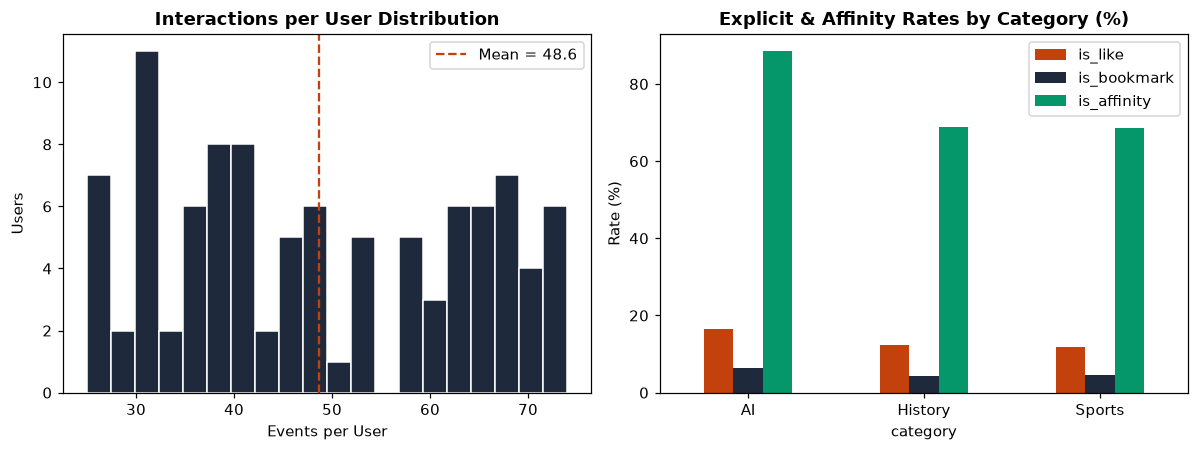

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
user_activity = df.groupby("user_id").size()
axes[0].hist(user_activity, bins=20, color="#1e293b", edgecolor="white")
axes[0].axvline(user_activity.mean(), color="#c2410c", linestyle="--", label=f"Mean = {user_activity.mean():.1f}")
axes[0].set_title("Interactions per User Distribution", fontweight="bold")
axes[0].set_xlabel("Events per User")
axes[0].set_ylabel("Users")
axes[0].legend()

cat_eng = df.groupby("category")[["is_like", "is_bookmark", "is_affinity"]].mean() * 100
cat_eng.plot(kind="bar", ax=axes[1], color=["#c2410c", "#1e293b", "#059669"])
axes[1].set_title("Explicit & Affinity Rates by Category (%)", fontweight="bold")
axes[1].set_ylabel("Rate (%)")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()